In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [2]:
grid_size = 4

start_state = 0
goal_state = 15

actions = {
    0: "Up",
    1: "Down",
    2: "Left",
    3: "Right"
}

n_states = grid_size * grid_size
n_actions = len(actions)

def reset():
    return start_state

def step(state, action):

    row = state // grid_size
    col = state % grid_size

    if action == 0:  # Up
        row = max(0, row - 1)

    elif action == 1:  # Down
        row = min(grid_size - 1, row + 1)

    elif action == 2:  # Left
        col = max(0, col - 1)

    elif action == 3:  # Right
        col = min(grid_size - 1, col + 1)

    next_state = row * grid_size + col

    if next_state == goal_state:
        reward = 10
        done = True
    else:
        reward = -1
        done = False

    return next_state, reward, done

In [3]:
q_table = np.zeros((n_states, n_actions))

print("Q-table shape:", q_table.shape)
print(q_table)

Q-table shape: (16, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [4]:
learning_rate = 0.1
discount_factor = 0.95

epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995

episodes = 500
max_steps = 50

scores = []

In [5]:
def choose_action(state, q_table, epsilon):

    if random.random() < epsilon:
        return random.randint(0, n_actions - 1)

    return np.argmax(q_table[state])

In [6]:
def update_q_value(
    q_table,
    state,
    action,
    reward,
    next_state,
    done,
    learning_rate,
    discount_factor
):

    if done:
        target = reward
    else:
        target = reward + discount_factor * np.max(q_table[next_state])

    q_table[state, action] += learning_rate * (
        target - q_table[state, action]
    )

    return q_table

In [7]:
scores = []
epsilon = 1.0

for episode in range(episodes):

    state = reset()
    total_reward = 0
    done = False

    for step_count in range(max_steps):

        action = choose_action(state, q_table, epsilon)

        next_state, reward, done = step(state, action)

        q_table = update_q_value(
            q_table,
            state,
            action,
            reward,
            next_state,
            done,
            learning_rate,
            discount_factor
        )

        state = next_state
        total_reward += reward

        if done:
            break

    scores.append(total_reward)

    # Reduce exploration over time
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    if (episode + 1) % 50 == 0:
        average_score = np.mean(scores[-50:])

        print(
            f"Episode {episode + 1}/{episodes} | "
            f"Average Reward: {average_score:.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )

Episode 50/500 | Average Reward: -20.64 | Epsilon: 0.778
Episode 100/500 | Average Reward: -5.88 | Epsilon: 0.606
Episode 150/500 | Average Reward: -0.36 | Epsilon: 0.471
Episode 200/500 | Average Reward: 1.24 | Epsilon: 0.367
Episode 250/500 | Average Reward: 2.90 | Epsilon: 0.286
Episode 300/500 | Average Reward: 3.78 | Epsilon: 0.222
Episode 350/500 | Average Reward: 3.74 | Epsilon: 0.173
Episode 400/500 | Average Reward: 4.02 | Epsilon: 0.135
Episode 450/500 | Average Reward: 4.42 | Epsilon: 0.105
Episode 500/500 | Average Reward: 4.52 | Epsilon: 0.082


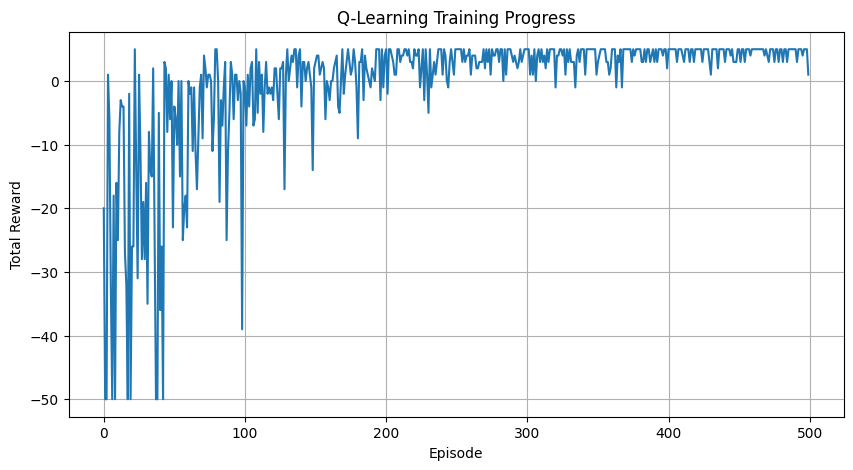

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(scores)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Q-Learning Training Progress")
plt.grid(True)

plt.show()

In [9]:
arrows = {
    0: "↑",
    1: "↓",
    2: "←",
    3: "→"
}

policy = np.empty((grid_size, grid_size), dtype="<U2")

for state in range(n_states):

    row = state // grid_size
    col = state % grid_size

    if state == goal_state:
        policy[row, col] = "G"
    else:
        best_action = np.argmax(q_table[state])
        policy[row, col] = arrows[best_action]

print("Learned Policy:")
print(policy)

Learned Policy:
[['→' '↓' '↓' '↓']
 ['→' '→' '↓' '↓']
 ['→' '→' '↓' '↓']
 ['→' '→' '→' 'G']]


In [10]:
state = reset()
path = [state]
done = False

for _ in range(max_steps):

    action = np.argmax(q_table[state])

    next_state, reward, done = step(state, action)

    path.append(next_state)
    state = next_state

    if done:
        break

print("Agent path:", path)
print("Reached goal:", state == goal_state)
print("Number of moves:", len(path) - 1)

Agent path: [0, 1, 5, 6, 10, 14, 15]
Reached goal: True
Number of moves: 6


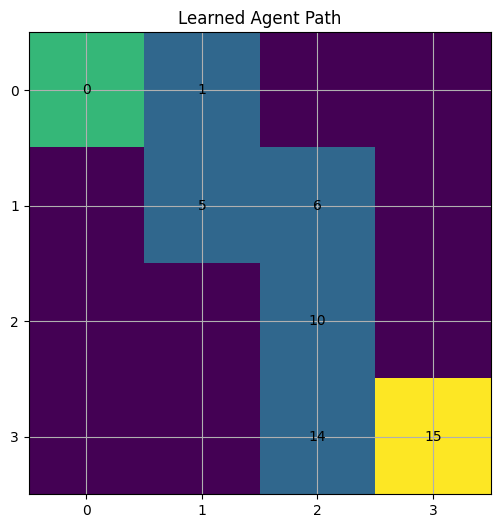

In [11]:
path_grid = np.zeros((grid_size, grid_size))

for state in path:

    row = state // grid_size
    col = state % grid_size

    path_grid[row, col] = 1

path_grid[start_state // grid_size, start_state % grid_size] = 2
path_grid[goal_state // grid_size, goal_state % grid_size] = 3

plt.figure(figsize=(6, 6))
plt.imshow(path_grid)

plt.xticks(range(grid_size))
plt.yticks(range(grid_size))
plt.grid(True)

for state in path:

    row = state // grid_size
    col = state % grid_size

    plt.text(col, row, str(state), ha="center", va="center")

plt.title("Learned Agent Path")
plt.show()